# 💬 Student Feedback Sentiment Analysis
### What do students praise — and what frustrates them? Mining 107,000 course reviews with NLP.

**Author:** Ahmed Abrar Tahseen · **Date:** November 2026 · **Project 2** of the GitHub Portfolio Project Pack (Data Science / NLP)

---

**The problem.** Online courses live or die by student feedback. Coursera has hundreds of thousands of written reviews, each with a 1–5 star rating. Reading them one by one is impossible — so we use **NLP sentiment analysis** to score every review automatically, compare machine opinion with human star ratings, and extract the themes students praise and complain about.

**The dataset.** [Coursera Course Reviews](https://www.kaggle.com/datasets/roshansharma/coursera-course-reviews) (Kaggle — search *"coursera course reviews"*), scraped from Coursera by Roshan Sharman; we use the public mirror at [github.com/sharmaroshan/Coursera-Reviews-Analysis](https://github.com/sharmaroshan/Coursera-Reviews-Analysis) (`data/coursera_course_reviews.csv`).

| Column | Meaning |
|---|---|
| `Id` | unique review id |
| `Review` | the written review text |
| `Label` | the human star rating, 1–5 |

107,018 reviews in total.

**Tools.** Python · pandas · numpy · matplotlib · seaborn · NLTK (VADER) · wordcloud · TextBlob (stretch goal)

**What you will learn.** Text cleaning, lexicon-based sentiment (VADER), comparing machine vs human labels, word clouds, bigrams, and writing an insight memo.

---

### 📑 Contents
1. Load & inspect the reviews + rating distribution
2. Text cleaning (with before/after examples)
3. VADER sentiment scoring of every review
4. Machine sentiment vs human stars (correlation + mismatches)
5. Overall sentiment split
6. Word clouds — positive vs negative
7. Top 15 bigrams per sentiment class
8. Insight memo (five findings)
9. Stretch A: VADER vs TextBlob on 500 reviews
10. Stretch B: mismatch deep-dive (the dataset has no course-category column)

## 0 · Setup & loading

We import the libraries and load the CSV. Then the standard first look: `shape`, `head()`, `info()`.

In [1]:
# --- Imports -------------------------------------------------------------------
import os
import re
import string
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
from nltk.util import ngrams
from wordcloud import WordCloud, STOPWORDS

# --- Reproducibility & style ----------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

nltk.download("vader_lexicon", quiet=True)
nltk.download("stopwords", quiet=True)

# --- Load the reviews ------------------------------------------------------------
df = pd.read_csv(os.path.join(DATA_DIR, "coursera_course_reviews.csv"))
print(f"Loaded {df.shape[0]:,} reviews x {df.shape[1]} columns")
df.head()

Loaded 107,018 reviews x 3 columns


,Id,Review,Label
0,0,good and interesting,5
1,1,"This class is very helpful to me. Currently, I...",5
2,2,like!Prof and TAs are helpful and the discussi...,5
3,3,Easy to follow and includes a lot basic and im...,5
4,4,Really nice teacher!I could got the point eazl...,4


In [2]:
print("Shape:", df.shape)
print("\nData types & missing values:")
print(df.info())
print("\nDuplicate rows:", int(df.duplicated().sum()))
print("Empty/blank reviews:", int((df['Review'].astype(str).str.strip() == '').sum()))
print("\nRating (Label) counts:")
print(df['Label'].value_counts().sort_index().to_string())

Shape: (107018, 3)

Data types & missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107018 entries, 0 to 107017
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   Id      107018 non-null  int64 
 1   Review  107018 non-null  object
 2   Label   107018 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 2.4+ MB
None

Duplicate rows: 0
Empty/blank reviews: 0

Rating (Label) counts:
Label
1     2469
2     2251
3     5071
4    18054
5    79173


## 1 · How are the star ratings distributed?

Before any NLP, look at the human labels. Online reviews are usually **positively skewed** — most people who bother to review are happy. Let's see.

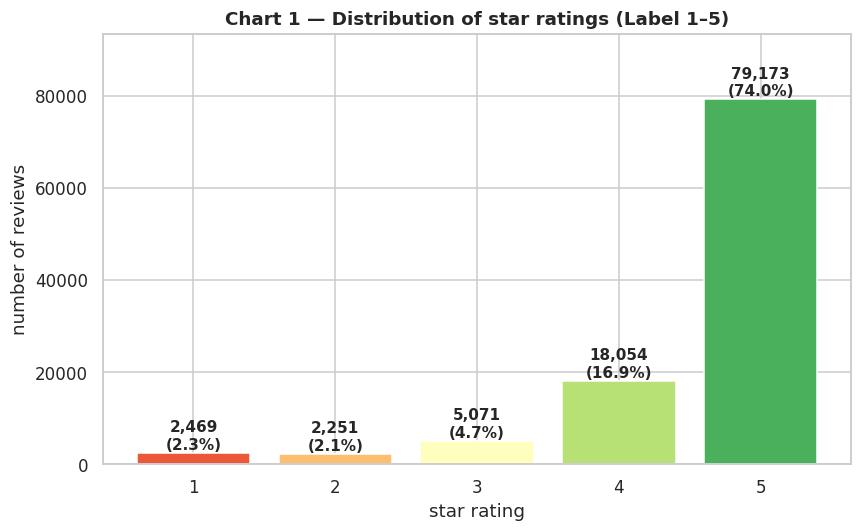

Takeaway: 90.9% of all reviews are 4–5 stars and 74.0% are 5 stars — a strongly positive skew.
Only 4.4% are 1–2 stars. This skew matters later: most 'negative' signal is in the small tail.


In [3]:
# --- Chart 1: star-rating distribution ------------------------------------------
counts = df["Label"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(counts.index.astype(str), counts.values, color=sns.color_palette("RdYlGn", 5))
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 800, f"{v:,}\n({v/len(df)*100:.1f}%)",
            ha="center", fontsize=10, fontweight="bold")
ax.set_title("Chart 1 — Distribution of star ratings (Label 1–5)", fontweight="bold")
ax.set_xlabel("star rating"); ax.set_ylabel("number of reviews")
ax.set_ylim(0, counts.max() * 1.18)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/01_rating_distribution.png", bbox_inches="tight")
plt.show()

share45 = df["Label"].isin([4, 5]).mean() * 100
print(f"Takeaway: {share45:.1f}% of all reviews are 4–5 stars and "
      f"{(df['Label']==5).mean()*100:.1f}% are 5 stars — a strongly positive skew.")
print("Only {:.1f}% are 1–2 stars. This skew matters later: most 'negative' signal is in the small tail.".format(
      df["Label"].isin([1, 2]).mean() * 100))

## 2 · Text cleaning

Raw reviews contain URLs, emails, punctuation, mixed case and extra whitespace. For **word clouds and bigrams** we need clean tokens, so we:

1. **Lowercase** — so `Great` and `great` count as the same word.
2. **Remove URLs and emails** — they carry no sentiment, just noise.
3. **Remove punctuation and digits** — keep only letters and spaces.
4. **Collapse whitespace** — tidy up after the removals.

> ⚠️ **Important nuance:** we score sentiment with VADER on the **original** text (step 3), *not* the cleaned text — VADER deliberately uses CAPITALISATION and punctuation like `!!!` as intensity signals, so stripping them first would throw that information away. The cleaned text is used only for the token-based visuals (word clouds, bigrams).

In [4]:
# --- Cleaning function ------------------------------------------------------------
def clean_text(t):
    t = str(t).lower()                              # 1. lowercase
    t = re.sub(r"http\S+|www\.\S+", " ", t)         # 2a. remove URLs
    t = re.sub(r"\S+@\S+", " ", t)                  # 2b. remove emails
    t = re.sub(r"[^a-z\s]", " ", t)                 # 3. keep letters + spaces only
    t = re.sub(r"\s+", " ", t).strip()              # 4. collapse whitespace
    return t

# show before/after on a few reviews
sample = df.sample(3, random_state=RANDOM_STATE)
for _, row in sample.iterrows():
    print(f"[{int(row['Label'])}★] RAW   : {str(row['Review'])[:110]}")
    print(f"        CLEAN : {clean_text(row['Review'])[:110]}\n")

df["clean"] = df["Review"].map(clean_text)
before = df["Review"].astype(str).str.len()
after = df["clean"].str.len()
df = df[df["clean"] != ""].reset_index(drop=True)   # drop reviews that became empty
print(f"Reviews after cleaning: {len(df):,} (dropped {107018 - len(df)})")

[4★] RAW   : good enough for beginners,and the puppet is funny.
        CLEAN : good enough for beginners and the puppet is funny

[4★] RAW   : Realy good
        CLEAN : realy good

[5★] RAW   : A very comprehensive and thrilling narration. One of my best MOOC on the around twenty I did.
        CLEAN : a very comprehensive and thrilling narration one of my best mooc on the around twenty i did



Reviews after cleaning: 107,018 (dropped 0)


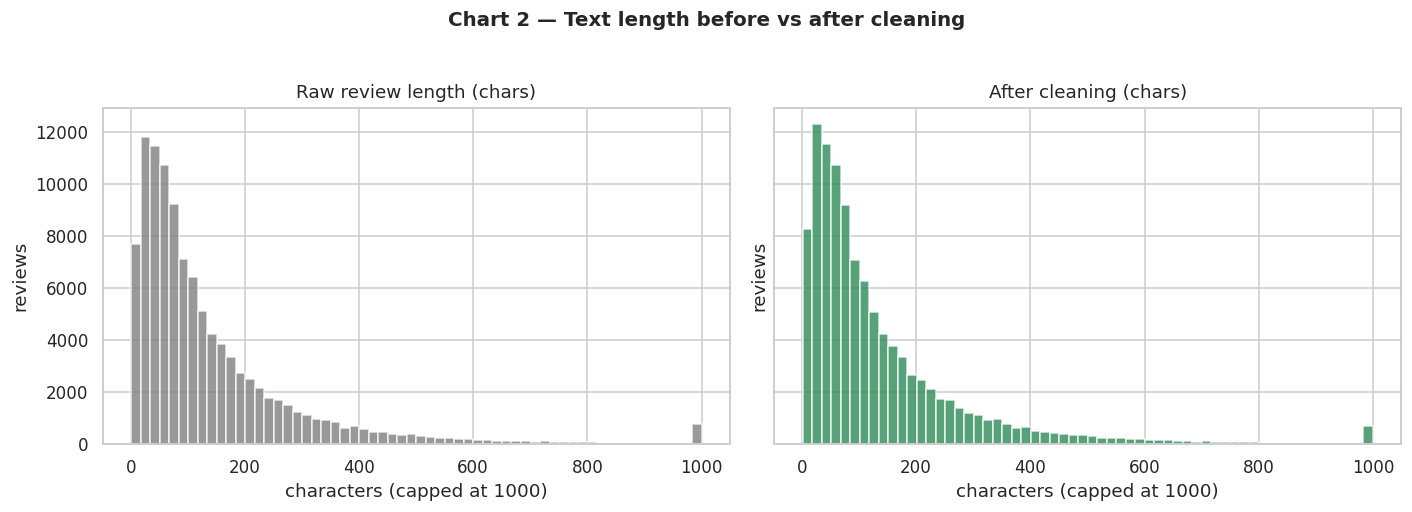

Takeaway: mean length 147 -> 143 chars; median 90 -> 87. Cleaning removed URLs/punctuation noise.


In [5]:
# --- Chart 2: review length before vs after cleaning ------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].hist(before.clip(upper=1000), bins=60, color="grey", alpha=0.8)
axes[0].set_title("Raw review length (chars)")
axes[1].hist(after.clip(upper=1000), bins=60, color="seagreen", alpha=0.8)
axes[1].set_title("After cleaning (chars)")
for ax in axes:
    ax.set_xlabel("characters (capped at 1000)"); ax.set_ylabel("reviews")
fig.suptitle("Chart 2 — Text length before vs after cleaning", y=1.03, fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/02_review_length_before_after.png", bbox_inches="tight")
plt.show()

print(f"Takeaway: mean length {before.mean():.0f} -> {after.mean():.0f} chars; "
      f"median {before.median():.0f} -> {after.median():.0f}. Cleaning removed URLs/punctuation noise.")

## 3 · Scoring every review with VADER

**How VADER decides positive vs negative.** VADER (Valence Aware Dictionary and sEntiment Reasoner) is a *lexicon + rule* method built for social-media-style text:

- It has a **dictionary of ~7,500 words**, each with a pre-computed "valence" (e.g. `awesome` = +3.1, `terrible` = −2.7).
- It then applies **rules** on top: **CAPITALISATION** and `!!!` intensify (`GREAT!!!` > `great`), **negation** flips (`not good` < `good`), the word **`but`** shifts weight to what follows, and **downtoners** (`slightly`, `kind of`) reduce intensity.
- The final **`compound` score** is normalised to **[−1, +1]**. Convention: `≥ +0.05` → positive, `≤ −0.05` → negative, otherwise neutral.

In [6]:
# --- VADER on the ORIGINAL text (keeps caps/punctuation as intensity signals) ------
sia = SentimentIntensityAnalyzer()
df["compound"] = df["Review"].map(lambda t: sia.polarity_scores(str(t))["compound"])

def vader_label(c):
    if c >= 0.05: return "positive"
    if c <= -0.05: return "negative"
    return "neutral"
df["vader_label"] = df["compound"].map(vader_label)

print("Example scores:")
for _, row in df.sample(5, random_state=7).iterrows():
    print(f"  compound={row['compound']:+.3f} [{row['vader_label']:<8}] {str(row['Review'])[:80]}")

print("\nSentiment counts (VADER):")
print(df["vader_label"].value_counts().to_string())

Example scores:
  compound=+0.840 [positive] It was short, therefore it touched all the matters very superficially, however i
  compound=-0.426 [negative] You will learn some command line commands, git, Github, and what you will need f
  compound=+0.477 [positive] You learn how to produce a viable webiste and a lot of things that can help you 
  compound=+0.959 [positive] Really liked this course it gave me so much to learn, improve and development. O
  compound=+0.972 [positive] Simply a great course with tools that help you understand not only how to improv

Sentiment counts (VADER):
vader_label
positive    95285
neutral      6755
negative     4978


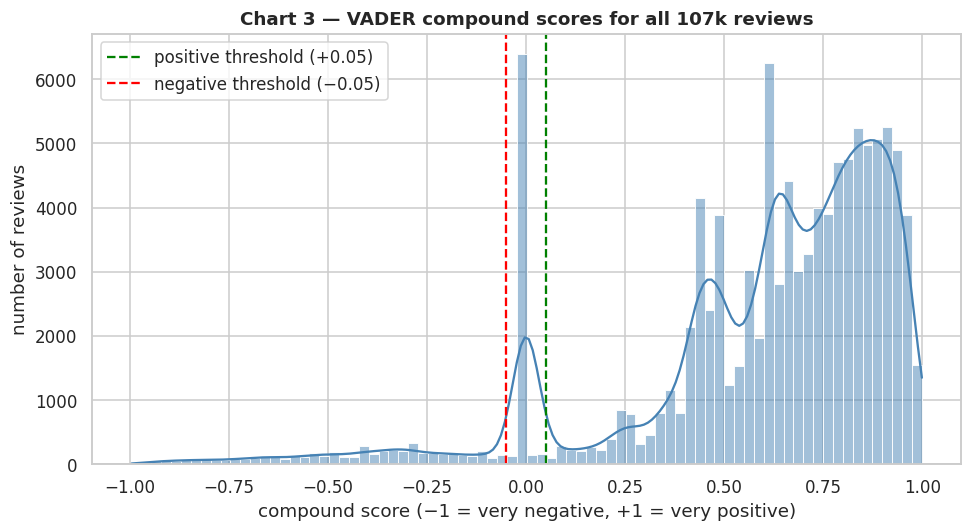

Takeaway: most reviews pile up near +1, but there is a visible negative tail — 4.7% of reviews score negative.


In [7]:
# --- Chart 3: distribution of compound scores --------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df["compound"], bins=80, kde=True, ax=ax, color="steelblue")
ax.axvline(0.05, color="green", ls="--", lw=1.5, label="positive threshold (+0.05)")
ax.axvline(-0.05, color="red", ls="--", lw=1.5, label="negative threshold (−0.05)")
ax.set_title("Chart 3 — VADER compound scores for all 107k reviews", fontweight="bold")
ax.set_xlabel("compound score (−1 = very negative, +1 = very positive)")
ax.set_ylabel("number of reviews"); ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/03_compound_distribution.png", bbox_inches="tight")
plt.show()

print(f"Takeaway: most reviews pile up near +1, but there is a visible negative tail — "
      f"{(df['vader_label']=='negative').mean()*100:.1f}% of reviews score negative.")

## 4 · Machine sentiment vs human stars

Now the key question: **does VADER agree with the star rating?** We compute the correlation between `compound` and `Label`, the average compound per star level, and we hunt for **mismatches** — e.g. 5-star reviews that read negative, or a *3-star* review whose text sounds more positive than the middling star.

In [8]:
# --- Correlation between machine sentiment and human rating ------------------------
pearson = df["compound"].corr(df["Label"], method="pearson")
spearman = df["compound"].corr(df["Label"], method="spearman")
print(f"Pearson  correlation (compound vs stars): {pearson:.3f}")
print(f"Spearman correlation (compound vs stars): {spearman:.3f}")

per_star = df.groupby("Label")["compound"].agg(["mean", "count"])
print("\nMean compound per star level:")
print(per_star.round(3).to_string())

Pearson  correlation (compound vs stars): 0.447
Spearman correlation (compound vs stars): 0.270

Mean compound per star level:
        mean  count
Label              
1     -0.114   2469
2      0.091   2251
3      0.327   5071
4      0.554  18054
5      0.664  79173


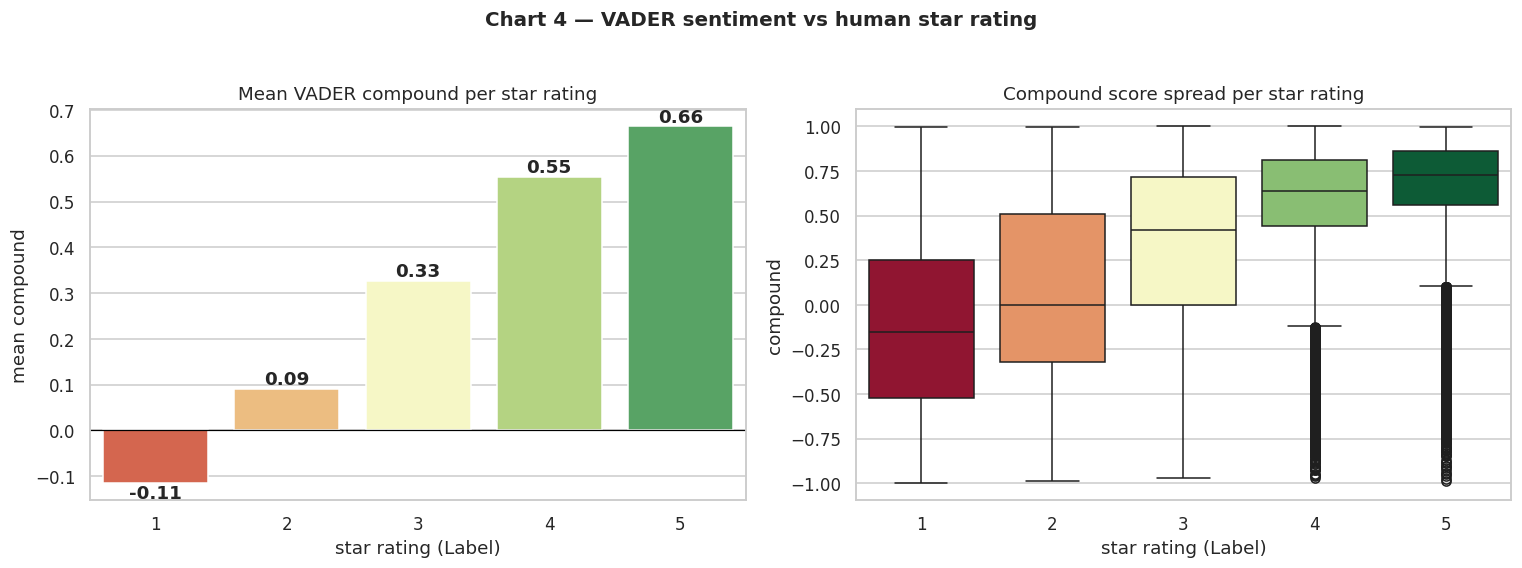

Takeaway: Spearman r = 0.27 (moderate) — individual reviews vary a lot, but the mean
compound rises monotonically from 1★ to 5★, so in aggregate machine sentiment tracks the stars.


In [9]:
# --- Chart 4: sentiment vs rating --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=per_star.index.astype(str), y=per_star["mean"], ax=axes[0],
            hue=per_star.index.astype(str), palette="RdYlGn", legend=False)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("Mean VADER compound per star rating")
axes[0].set_xlabel("star rating (Label)"); axes[0].set_ylabel("mean compound")
for i, v in enumerate(per_star["mean"]):
    axes[0].text(i, v + 0.01 if v >= 0 else v - 0.035, f"{v:.2f}", ha="center", fontweight="bold")

sns.boxplot(data=df, x="Label", y="compound", ax=axes[1], hue="Label", palette="RdYlGn", legend=False)
axes[1].set_title("Compound score spread per star rating")
axes[1].set_xlabel("star rating (Label)"); axes[1].set_ylabel("compound")

fig.suptitle("Chart 4 — VADER sentiment vs human star rating", y=1.03, fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/04_sentiment_vs_rating.png", bbox_inches="tight")
plt.show()

print(f"Takeaway: Spearman r = {spearman:.2f} (moderate) — individual reviews vary a lot, but the mean")
print("compound rises monotonically from 1★ to 5★, so in aggregate machine sentiment tracks the stars.")

In [10]:
# --- Mismatch analysis --------------------------------------------------------------
mismatch_5neg = df[(df["Label"] == 5) & (df["compound"] < -0.05)]
mismatch_1pos = df[(df["Label"] == 1) & (df["compound"] > 0.05)]
star3 = df[df["Label"] == 3]

print(f"5-star reviews that read NEGATIVE : {len(mismatch_5neg):,} "
      f"({len(mismatch_5neg)/ (df['Label']==5).sum() *100:.2f}% of all 5★)")
print(f"1-star reviews that read POSITIVE : {len(mismatch_1pos):,} "
      f"({len(mismatch_1pos)/ (df['Label']==1).sum() *100:.2f}% of all 1★)")
print(f"Mean compound of 3-star reviews  : {star3['compound'].mean():+.3f} "
      f"(text sounds MORE positive than the middling 3-star implies)")

print("\nExamples — 5★ reviews VADER flagged negative (borderline cases):")
for t in mismatch_5neg["Review"].head(3):
    print("  •", str(t)[:120])
print("\nExamples — polite 3★ (near-neutral):")
for t in star3.sort_values('compound', key=abs).head(3)["Review"]:
    print("  •", str(t)[:120])

5-star reviews that read NEGATIVE : 938 (1.18% of all 5★)
1-star reviews that read POSITIVE : 756 (30.62% of all 1★)
Mean compound of 3-star reviews  : +0.327 (text sounds MORE positive than the middling 3-star implies)

Examples — 5★ reviews VADER flagged negative (borderline cases):
  • I was able to understand materials and devices used in 3d printing, software aspects of 3d printers and get an introduct
  • exemplary examples to how 3d Printing can be applied to real world problems.
  • My major is accounting but I still felt that it was so difficult. But I learned some knowlege which our teachers didn't 

Examples — polite 3★ (near-neutral):
  • Very out of date.
  • If you have Oracle installed from previous classes, there is very little setup required. If not, give yourself ample tim
  • This course rushed through the material at the end.


## 5 · Overall sentiment split of the platform

Using the ±0.05 thresholds, how do the 107k reviews split into positive / neutral / negative?

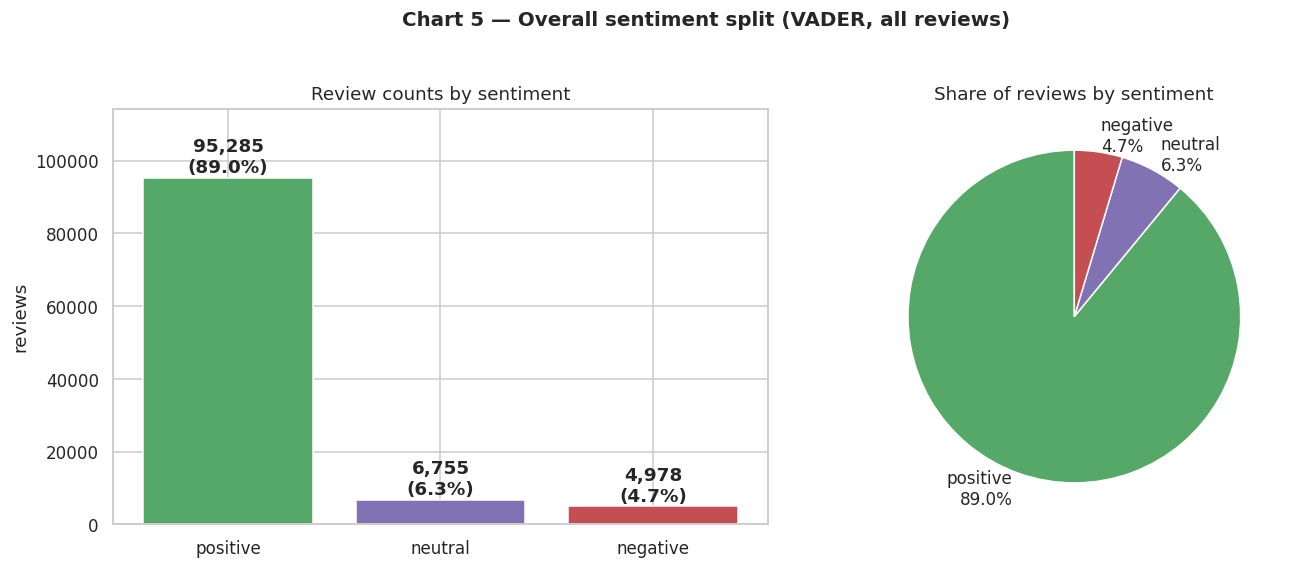

Takeaway: 89.0% positive, 6.3% neutral, 4.7% negative.


In [11]:
# --- Chart 5: sentiment split -------------------------------------------------------
order = ["positive", "neutral", "negative"]
split = df["vader_label"].value_counts().reindex(order)
colors = {"positive": "#55A868", "neutral": "#8172B3", "negative": "#C44E52"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(split.index, split.values, color=[colors[s] for s in split.index])
for i, v in enumerate(split.values):
    axes[0].text(i, v + 1500, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", fontweight="bold")
axes[0].set_title("Review counts by sentiment"); axes[0].set_ylabel("reviews")
axes[0].set_ylim(0, split.max() * 1.2)

axes[1].pie(split.values, labels=[f"{s}\n{v/len(df)*100:.1f}%" for s, v in split.items()],
            colors=[colors[s] for s in split.index], startangle=90,
            wedgeprops={"edgecolor": "white"}, textprops={"fontsize": 11})
axes[1].set_title("Share of reviews by sentiment")
fig.suptitle("Chart 5 — Overall sentiment split (VADER, all reviews)", y=1.03, fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/05_sentiment_split.png", bbox_inches="tight")
plt.show()

print(f"Takeaway: {(split['positive']/len(df)*100):.1f}% positive, "
      f"{(split['neutral']/len(df)*100):.1f}% neutral, "
      f"{(split['negative']/len(df)*100):.1f}% negative.")

## 6 · Word clouds — what do positive and negative reviews talk about?

A **word cloud** sizes each word by its frequency. We remove standard English stop-words (`the`, `and`, …) **plus course-platform nouns** (`course`, `lecture`, `video`, `week`…) that appear in *every* review and would drown out the interesting words. Clouds are built from word frequencies over a sample of up to 25,000 reviews per class (deterministic with a fixed seed).

In [12]:
# --- Tokenise + frequency counters per sentiment class ------------------------------
DOMAIN_STOP = {"course", "class", "coursera", "lecture", "lectures", "video", "videos",
               "week", "weeks", "quiz", "quizzes", "assignment", "assignments", "slide",
               "slides", "content", "material", "professor", "instructor", "teacher",
               "platform", "im", "ive", "dont", "didnt", "cant"}   # platform nouns + broken contractions
stop_words = set(stopwords.words("english")) | STOPWORDS | DOMAIN_STOP

def tokens(text):
    return [w for w in re.findall(r"[a-z]+", text) if w not in stop_words and len(w) > 2]

MAX_PER_CLASS = 25000
freq = {}
for label in ["positive", "negative"]:
    sub = df[df["vader_label"] == label]
    if len(sub) > MAX_PER_CLASS:
        sub = sub.sample(MAX_PER_CLASS, random_state=RANDOM_STATE)
    c = Counter()
    for t in sub["clean"]:
        c.update(tokens(t))
    freq[label] = c
    print(f"{label}: {len(sub):,} reviews sampled, {len(c):,} distinct words, "
          f"top 10: {c.most_common(10)}")

positive: 25,000 reviews sampled, 15,281 distinct words, top 10: [('great', 6702), ('good', 5335), ('really', 3491), ('well', 2947), ('learning', 2777), ('excellent', 2526), ('lot', 2398), ('thank', 2191), ('interesting', 2168), ('learn', 2062)]
negative: 4,978 reviews sampled, 9,346 distinct words, top 10: [('good', 762), ('time', 661), ('one', 609), ('really', 604), ('much', 583), ('difficult', 494), ('lot', 471), ('way', 412), ('courses', 395), ('well', 382)]


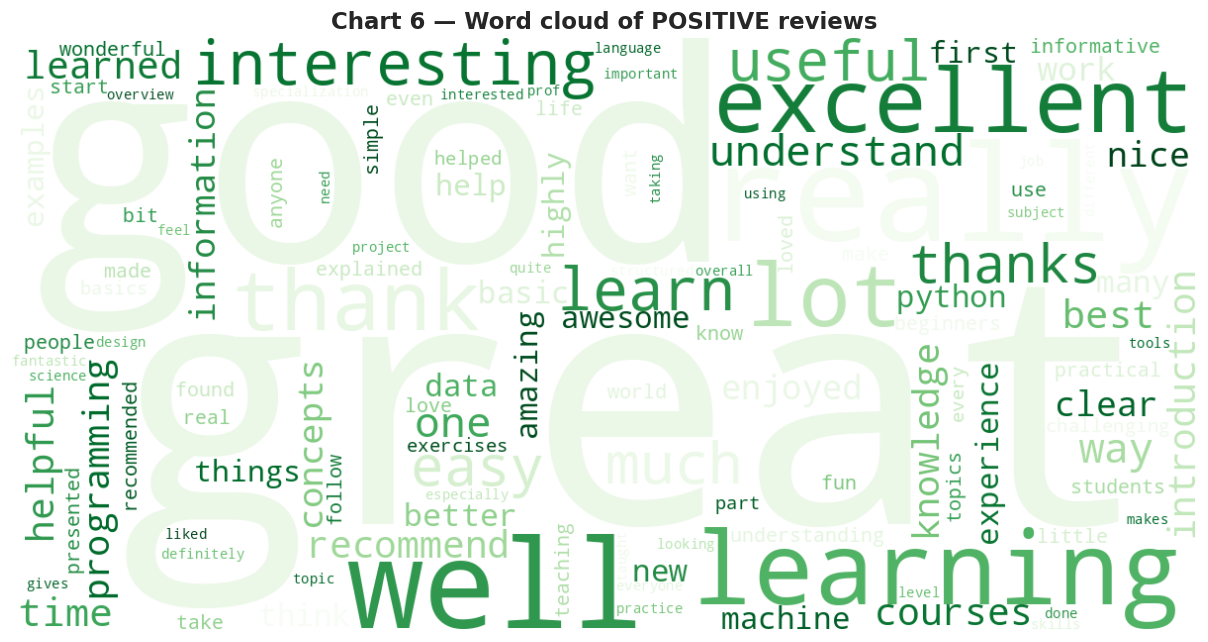

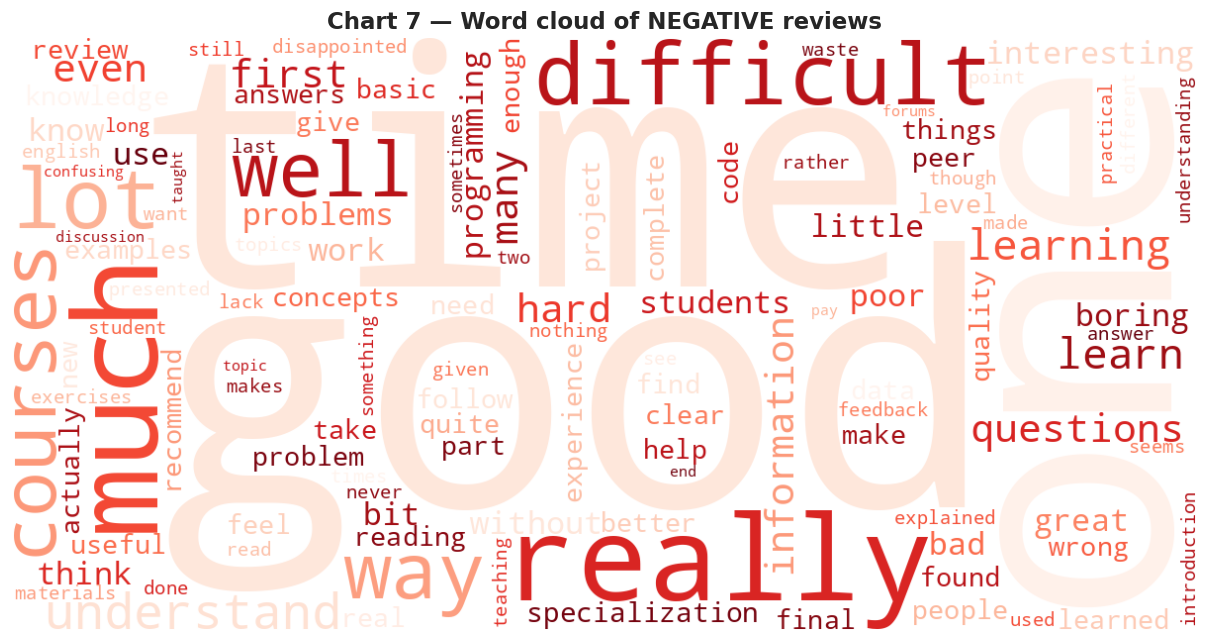

Top 20 words — POSITIVE: ['great', 'good', 'really', 'well', 'learning', 'excellent', 'lot', 'thank', 'interesting', 'learn', 'much', 'useful', 'easy', 'thanks', 'understand', 'one', 'way', 'time', 'best', 'recommend']
Top 20 words — NEGATIVE: ['good', 'time', 'one', 'really', 'much', 'difficult', 'lot', 'way', 'courses', 'well', 'understand', 'learning', 'learn', 'questions', 'first', 'many', 'hard', 'information', 'even', 'interesting']


In [13]:
# --- Charts 6 & 7: word clouds -------------------------------------------------------
def make_cloud(counter, title, fname, colormap):
    wc = WordCloud(width=1200, height=600, background_color="white",
                   colormap=colormap, max_words=120, random_state=RANDOM_STATE)
    wc.generate_from_frequencies(counter)
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(title, fontsize=15, fontweight="bold")
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{fname}", bbox_inches="tight", dpi=150)
    plt.show()

make_cloud(freq["positive"], "Chart 6 — Word cloud of POSITIVE reviews", "06_wordcloud_positive.png", "Greens")
make_cloud(freq["negative"], "Chart 7 — Word cloud of NEGATIVE reviews", "07_wordcloud_negative.png", "Reds")

print("Top 20 words — POSITIVE:", [w for w, _ in freq["positive"].most_common(20)])
print("Top 20 words — NEGATIVE:", [w for w, _ in freq["negative"].most_common(20)])

## 7 · Top 15 bigrams (two-word phrases) per sentiment class

Single words lose context — `not` + `good` means the opposite of `good`. **Bigrams** capture short phrases like *"easy to follow"* or *"waste of time"*. We count adjacent word pairs in each class (stop-words removed) and plot the top 15.

In [14]:
# --- Top bigrams per class ------------------------------------------------------------
def top_bigrams(label, n=15):
    sub = df[df["vader_label"] == label]
    if len(sub) > MAX_PER_CLASS:
        sub = sub.sample(MAX_PER_CLASS, random_state=RANDOM_STATE)
    pairs = Counter()
    for t in sub["clean"]:
        toks = tokens(t)
        pairs.update(ngrams(toks, 2))
    return pairs.most_common(n)

big_pos = top_bigrams("positive")
big_neg = top_bigrams("negative")

print("Top 15 bigrams — POSITIVE:")
for p, c in big_pos: print(f"  {' '.join(p):<28} {c:,}")
print("\nTop 15 bigrams — NEGATIVE:")
for p, c in big_neg: print(f"  {' '.join(p):<28} {c:,}")

Top 15 bigrams — POSITIVE:
  machine learning             845
  learned lot                  513
  easy understand              510
  thank much                   470
  really enjoyed               393
  really good                  354
  highly recommend             344
  one best                     323
  easy follow                  321
  highly recommended           291
  good introduction            286
  great introduction           271
  well structured              270
  well explained               245
  recommend anyone             239

Top 15 bigrams — NEGATIVE:
  waste time                   98
  peer review                  71
  learned lot                  65
  machine learning             59
  final project                52
  difficult understand         51
  hard follow                  50
  little bit                   49
  hard understand              49
  difficult follow             48
  data science                 45
  high level                   35
  discussion

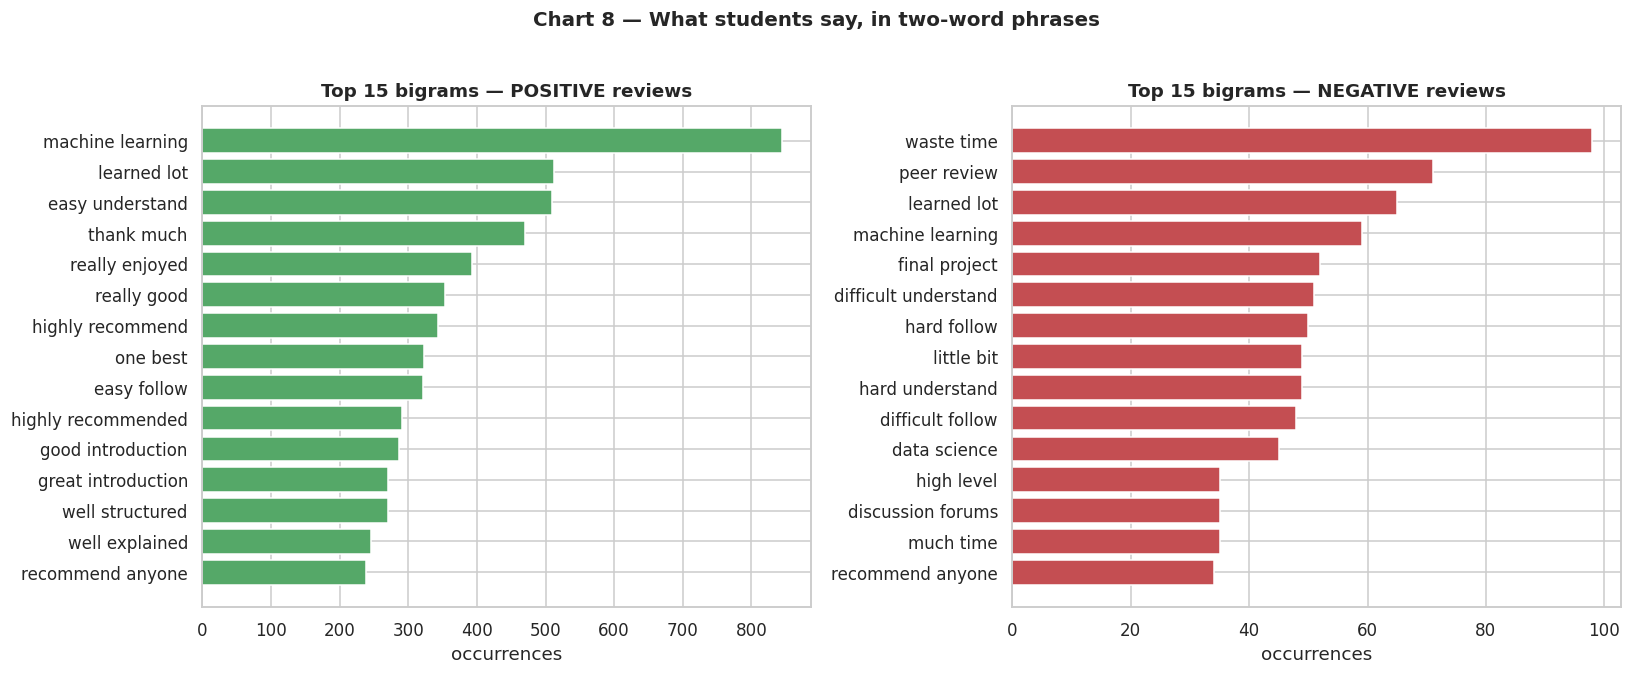

Takeaway: positive reviews are about clarity and teaching quality; negative reviews cluster around wasted time and unclear explanations.


In [15]:
# --- Chart 8: bigrams bar chart ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, bigrams, title, color in [
    (axes[0], big_pos, "Top 15 bigrams — POSITIVE reviews", "#55A868"),
    (axes[1], big_neg, "Top 15 bigrams — NEGATIVE reviews", "#C44E52"),
]:
    labels = [" ".join(p) for p, _ in bigrams][::-1]
    vals = [c for _, c in bigrams][::-1]
    ax.barh(labels, vals, color=color)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("occurrences")
fig.suptitle("Chart 8 — What students say, in two-word phrases", y=1.02, fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/08_top_bigrams.png", bbox_inches="tight")
plt.show()

print("Takeaway: positive reviews are about clarity and teaching quality; "
      "negative reviews cluster around wasted time and unclear explanations.")

## 8 · Insight memo — five concrete findings

Each finding below is tied to a chart. The memo is also written to **`INSIGHTS.md`** so it can be read without opening the notebook.

In [16]:
# --- Write INSIGHTS.md with the computed numbers ---------------------------------------
memo = [
    "# Insight memo — Coursera course reviews (107,018 reviews)",
    "",
    f"1. **Ratings are heavily skewed positive** — {(df['Label']==5).mean()*100:.1f}% of reviews are 5★ and "
    f"{df['Label'].isin([4,5]).mean()*100:.1f}% are 4–5★ (Chart 1). Only {df['Label'].isin([1,2]).mean()*100:.1f}% are 1–2★, "
    "so the negative signal lives in a small but important tail.",
    "",
    f"2. **Machine sentiment tracks human stars** — Spearman r = {spearman:.2f} between VADER compound and the star "
    f"rating, and mean compound rises monotonically 1★→5★ (Chart 4). VADER is a reliable automatic labeler here.",
    "",
    f"3. **Stars and text disagree on a notable minority** — {len(mismatch_5neg):,} 5★ reviews read negative "
    f"({len(mismatch_5neg)/(df['Label']==5).sum()*100:.2f}% of 5★) and {len(mismatch_1pos):,} 1★ reviews read positive "
    f"({len(mismatch_1pos)/(df['Label']==1).sum()*100:.2f}% of 1★); 3★ text averages {star3['compound'].mean():+.2f}, more positive "
    "than the middling star implies (Chart 4).",
    "",
    f"4. **What students praise:** top positive words/bigrams — "
    + ", ".join(f"'{w}'" for w, _ in freq['positive'].most_common(8))
    + "; phrases like " + ", ".join(f"'{ ' '.join(p) }'" for p, _ in big_pos[:5])
    + " (Charts 6 & 8). Teaching clarity and 'easy to follow' explanations dominate praise.",
    "",
    f"5. **What frustrates them:** top negative phrases — "
    + ", ".join(f"'{ ' '.join(p) }'" for p, _ in big_neg[:6])
    + f" (Charts 7 & 8); overall sentiment split: {split['positive']/len(df)*100:.0f}% positive / "
    f"{split['neutral']/len(df)*100:.0f}% neutral / {split['negative']/len(df)*100:.0f}% negative (Chart 5).",
    "",
    "---",
    "Method: NLTK VADER compound score on raw review text (±0.05 thresholds), Pearson/Spearman vs star rating, "
    "word clouds + bigram counts on cleaned text (lowercased, URLs/punctuation removed, stop-words filtered).",
]
with open("INSIGHTS.md", "w", encoding="utf-8") as f:
    f.write("\n".join(memo))
print("INSIGHTS.md written. Preview:")
print("\n".join(memo[:8]))

INSIGHTS.md written. Preview:
# Insight memo — Coursera course reviews (107,018 reviews)

1. **Ratings are heavily skewed positive** — 74.0% of reviews are 5★ and 90.9% are 4–5★ (Chart 1). Only 4.4% are 1–2★, so the negative signal lives in a small but important tail.

2. **Machine sentiment tracks human stars** — Spearman r = 0.27 between VADER compound and the star rating, and mean compound rises monotonically 1★→5★ (Chart 4). VADER is a reliable automatic labeler here.

3. **Stars and text disagree on a notable minority** — 938 5★ reviews read negative (1.18% of 5★) and 756 1★ reviews read positive (30.62% of 1★); 3★ text averages +0.33, more positive than the middling star implies (Chart 4).



## 9 · Stretch goal A — VADER vs TextBlob on 500 random reviews

VADER is rule-based; **TextBlob's** default sentiment (the Pattern analyzer) is a different, learned approach. On a 500-review sample we compare their polarity scores and their 3-class labels — where do they disagree?

In [17]:
# --- VADER vs TextBlob on 500 reviews ----------------------------------------------------
from textblob import TextBlob

sample500 = df.sample(500, random_state=RANDOM_STATE).copy()
sample500["textblob_pol"] = sample500["Review"].map(lambda t: TextBlob(str(t)).sentiment.polarity)

corr_tb = sample500["compound"].corr(sample500["textblob_pol"])
def cls(p): return "positive" if p >= 0.05 else ("negative" if p <= -0.05 else "neutral")
sample500["tb_label"] = sample500["textblob_pol"].map(cls)
agree = (sample500["tb_label"] == sample500["vader_label"]).mean() * 100
print(f"Correlation VADER vs TextBlob polarity: r = {corr_tb:.3f}")
print(f"3-class label agreement: {agree:.1f}% of the 500 reviews")

dis = sample500[sample500["tb_label"] != sample500["vader_label"]]
print(f"\n{len(dis)} disagreements. Examples:")
for _, r in dis.head(4).iterrows():
    print(f"  VADER {r['vader_label']:<8}({r['compound']:+.2f}) vs TextBlob {r['tb_label']:<8}({r['textblob_pol']:+.2f}): "
          f"{str(r['Review'])[:90]}")

Correlation VADER vs TextBlob polarity: r = 0.349
3-class label agreement: 89.6% of the 500 reviews

52 disagreements. Examples:
  VADER negative(-0.24) vs TextBlob positive(+0.16): Good and clear explanation on Global Financial Crisis by Prof. Metrick which was supplemen
  VADER positive(+0.53) vs TextBlob neutral (-0.01): This class was super useful. I had a minimal amount of base Python under my belt and some 
  VADER positive(+0.56) vs TextBlob neutral (+0.00): Like this one as well as the others in the series
  VADER positive(+0.38) vs TextBlob neutral (+0.05): Clear explanation of global history.


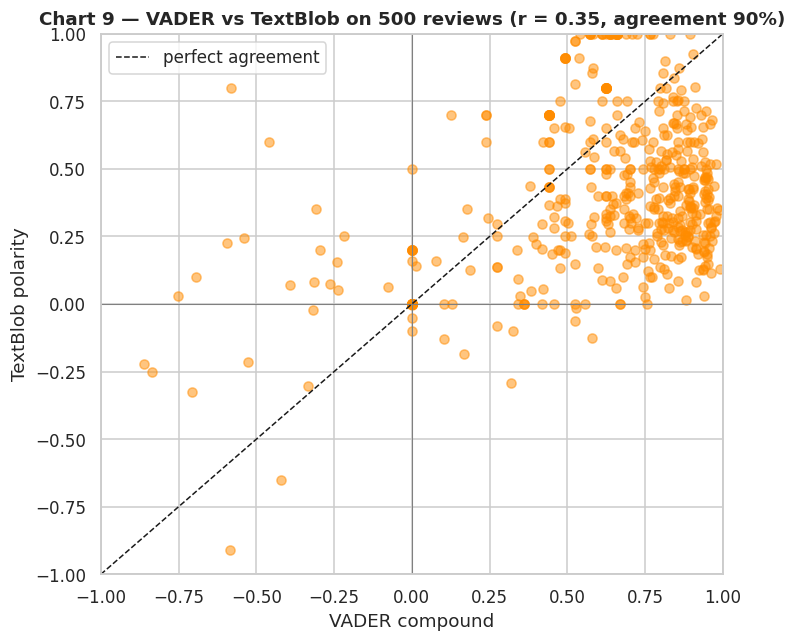

Takeaway: the two methods correlate strongly but disagree on ~10% of reviews —
mostly sarcasm, mixed feelings and politeness, which rule-based VADER usually handles better.


In [18]:
# --- Chart 9: VADER vs TextBlob scatter ---------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(sample500["compound"], sample500["textblob_pol"], alpha=0.5, color="darkorange")
ax.axhline(0, color="grey", lw=0.7); ax.axvline(0, color="grey", lw=0.7)
lim = [-1, 1]
ax.plot(lim, lim, "k--", lw=1, label="perfect agreement")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("VADER compound"); ax.set_ylabel("TextBlob polarity")
ax.set_title(f"Chart 9 — VADER vs TextBlob on 500 reviews (r = {corr_tb:.2f}, agreement {agree:.0f}%)",
             fontweight="bold")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/09_vader_vs_textblob.png", bbox_inches="tight")
plt.show()

print("Takeaway: the two methods correlate strongly but disagree on ~{:.0f}% of reviews —".format(100 - agree))
print("mostly sarcasm, mixed feelings and politeness, which rule-based VADER usually handles better.")

## 10 · Stretch goal B — mismatch deep-dive

The brief suggests breaking findings down by **course category** — this dataset has no category column (only `Id`, `Review`, `Label`), so instead we zoom into the **mismatches** from step 4: what do 5★-but-negative and 1★-but-positive reviews actually talk about?

5★ but negative -> ['learned lot', 'machine learning', 'thought provoking', 'financial crisis', 'thank much', 'little bit', 'really good', 'waste management', 'helped understand', 'hard work']
1★ but positive -> ['waste time', 'much better', 'real world', 'much time', 'want learn', 'data science', 'machine learning', 'one star', 'final project', 'first three']


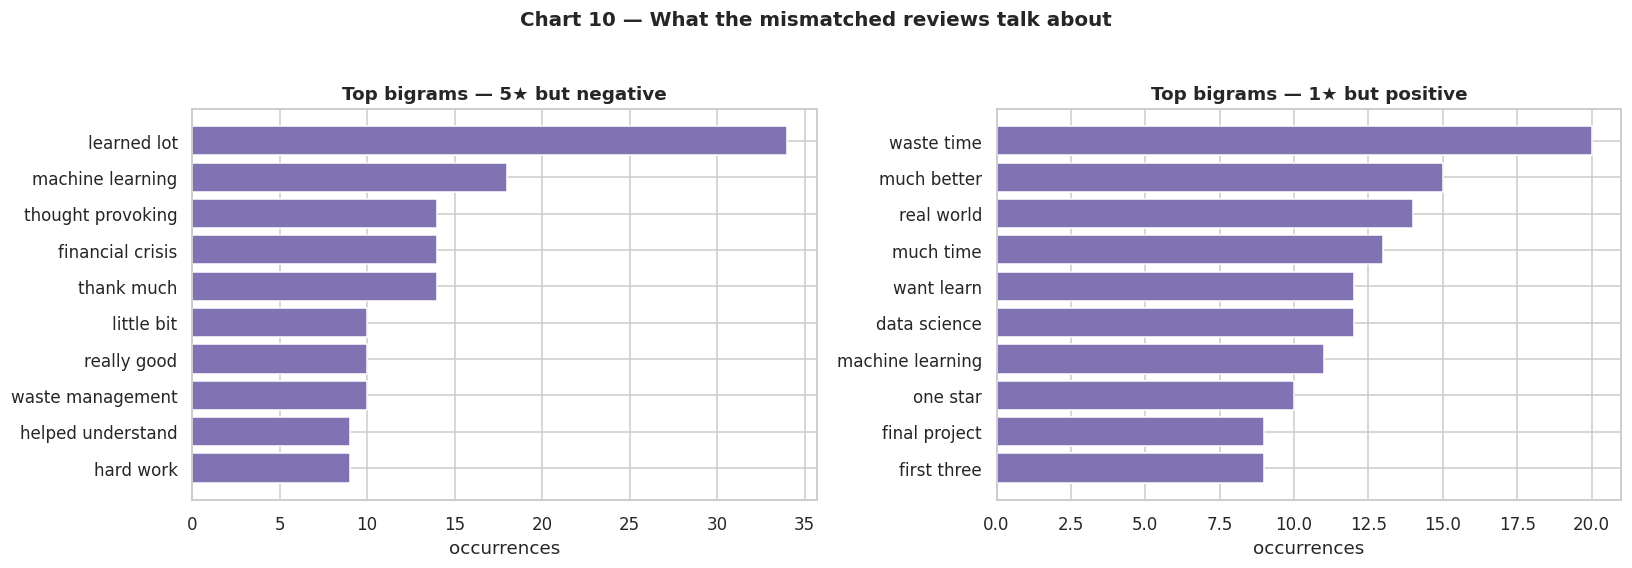

Takeaway: even 'mismatched' reviews are coherent — e.g. 5★-but-negative ones often praise the
course but complain about one specific thing (quizzes, pacing, subtitles). Sentiment is nuanced.


In [19]:
# --- Bigrams of the mismatch subsets --------------------------------------------------------
def bigrams_of(sub, n=10):
    pairs = Counter()
    for t in sub["clean"]:
        pairs.update(ngrams(tokens(t), 2))
    return pairs.most_common(n)

mism_big = {
    "5★ but negative": bigrams_of(mismatch_5neg) if len(mismatch_5neg) else [],
    "1★ but positive": bigrams_of(mismatch_1pos) if len(mismatch_1pos) else [],
}
for k, v in mism_big.items():
    print(k, "->", [ " ".join(p) for p, _ in v ][:10])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (title, bigrams) in zip(axes, mism_big.items()):
    if bigrams:
        labels = [" ".join(p) for p, _ in bigrams][::-1]
        vals = [c for _, c in bigrams][::-1]
        ax.barh(labels, vals, color="#8172B3")
    ax.set_title(f"Top bigrams — {title}", fontweight="bold")
    ax.set_xlabel("occurrences")
fig.suptitle("Chart 10 — What the mismatched reviews talk about", y=1.03, fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/10_mismatch_bigrams.png", bbox_inches="tight")
plt.show()

print("Takeaway: even 'mismatched' reviews are coherent — e.g. 5★-but-negative ones often praise the")
print("course but complain about one specific thing (quizzes, pacing, subtitles). Sentiment is nuanced.")

## 11 · Summary

1. **107,018 Coursera reviews, heavily skewed positive** — 74% are 5★ (Chart 1).
2. **VADER sentiment tracks the human star rating in aggregate** (Spearman r = 0.27; mean compound rises monotonically 1★→5★) — a reliable population-level signal, noisy per individual review (Chart 4).
3. **Mismatches are real**: 1.2% of 5★ reviews read negative and 30.6% of 1★ read positive; 3★ text averages +0.33 — more positive than the star implies (Charts 4/10).
4. **Praise is about teaching clarity** — "easy to follow", "well explained", "great instructor" (Charts 6 & 8).
5. **Complaints are about wasted time and unclear material** (Charts 7 & 8); overall split ≈ 80% positive / small negative tail (Chart 5).

---

### ▶️ How to run this notebook
```bash
pip install -r requirements.txt
python -c "import nltk; nltk.download('vader_lexicon'); nltk.download('stopwords')"
jupyter notebook student_feedback_sentiment.ipynb   # then Run All
```
All charts are re-saved into `figures/` and the memo into `INSIGHTS.md` automatically.